# Income and Adult Characteristics
## ANA500 Micro-Project 2
Douglas Bobeck · September 24, 2026

This notebook covers **Acquire, Prepare, Analyze, and Report**. The work uses
Jupyter Notebook, Pandas, NumPy, Matplotlib, and Seaborn.

## Summary
In this sample, 24.1% of adults earn above $50,000. The percentage differs across
age, education, occupation, and work hours. For example, the rate is 38.8% for
ages 45-59 and 40.2% for people working over 40 hours per week.

Looking at characteristics together adds detail: the rate is 72.7% for adults
ages 45-59 with a bachelor's degree or higher who work over 40 hours (n=1,089).
These are descriptive associations in the historical sample. They support examining
several variables together in a later classification analysis.

## Problem statement and hypothesis
**Problem:** Income differs across adults with different backgrounds and jobs.
Which demographic, educational, and employment characteristics occur together
with earning more than $50,000 per year in the Adult dataset?

**Hypothesis:** Higher income will be more common among adults with more education,
middle-career ages, professional or managerial jobs, and longer workweeks.
The differences will also appear when age, education, and work hours are considered together.
More education and experience may help people qualify for higher-paying jobs,
while hours worked may contribute to annual income. These are possible explanations.

### Method and assumptions
- Compare percentages within groups, using all records in each group as the denominator.
- Examine age, sex, education, occupation, and weekly work hours. Include workclass
  and marital status as additional descriptive tables.
- Use grouped summaries and a stratified heatmap to examine combinations.
  This is exploratory analysis. A classifier and formal hypothesis test are left for later work.
- Count each row equally. `fnlwgt` is retained but is not used for population estimates.
- Keep missing categories visible and retain repeated profiles because there is no person ID.
- Treat the records as a historical 1994 sample. Associations do not establish causes.

## 1. Acquire
The input is the same local Adult income CSV used for Week 1: 32,561 records and
15 fields. It matches UCI's training split. The separate test split is not used.
The original CSV is read without changing it.

**Source:** Becker, B., & Kohavi, R. (1996). *Adult* [Dataset].
[UCI Machine Learning Repository](https://doi.org/10.24432/C5XW20), CC BY 4.0.
[Attribute definitions and survey weights](https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.names).

In [1]:
# Load the libraries used for data preparation, plots, and saved results.
from pathlib import Path
import hashlib
import json
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns
from IPython.display import display, Markdown
%matplotlib inline

# Allow the notebook to open from the repository or the course Week 2 folder.
week_dir = Path.cwd()
if (week_dir / "week2").is_dir():
    week_dir = week_dir / "week2"
candidates = [week_dir.parent / "data/adult_income.csv",
              week_dir.parent / "adult income.csv"]
data_file = next((p for p in candidates if p.is_file()), None)
if data_file is None:
    raise FileNotFoundError("Open the notebook in week2 beside the original data folder.")
source_hash = hashlib.sha256(data_file.read_bytes()).hexdigest()
assert source_hash == "f2c62076f19504d99a38b22badf445a7f42530ade6b827acf78dd143fbce38bb"
raw = pd.read_csv(data_file, dtype="string", keep_default_na=False)
output_dir = week_dir / "outputs"
output_dir.mkdir(exist_ok=True)

# Record versions so the environment used for this work is clear.
versions = {"Python": platform.python_version(), "Pandas": pd.__version__,
            "NumPy": np.__version__, "Matplotlib": matplotlib.__version__,
            "Seaborn": sns.__version__}
print(f"Input: {len(raw):,} records and {len(raw.columns)} columns")
print("Tools:", versions)
display(raw.head(3))

Input: 32,561 records and 15 columns
Tools: {'Python': '3.11.5', 'Pandas': '2.2.2', 'NumPy': '1.26.4', 'Matplotlib': '3.8.4', 'Seaborn': '0.12.2'}


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K


## 2. Prepare
Remove extra spaces, identify missing values, and check the fields before making comparisons.
Missing workclass, occupation, and native-country values remain missing in the original fields.
The occupation chart labels missing records as **Unknown** so those rows stay in the denominator.

In [2]:
# Check the expected fields before changing any values.
columns = ("age workclass fnlwgt education education-num marital-status occupation "
           "relationship race sex capital-gain capital-loss hours-per-week "
           "native-country income").split()
assert list(raw.columns) == columns and raw.shape == (32561, 15)
data = raw.copy(deep=True)
for column in columns:
    data[column] = data[column].str.strip().replace({"?": pd.NA, "": pd.NA})
missing = data.isna().sum()
assert data[["age", "education", "education-num", "sex", "hours-per-week", "income"]].notna().all().all()
assert data["income"].isin(["<=50K", ">50K"]).all()
assert data["sex"].isin(["Female", "Male"]).all()

# Reject invalid numbers rather than silently changing them.
numeric = ["age", "fnlwgt", "education-num", "capital-gain", "capital-loss", "hours-per-week"]
for column in numeric:
    values = pd.to_numeric(data[column], errors="raise")
    assert np.isfinite(values).all() and (values % 1 == 0).all()
    data[column] = values.astype("int64")
values = data[numeric].to_numpy()
assert ((values >= [17, 1, 1, 0, 0, 1]) &
        (values <= [120, np.inf, 16, np.inf, np.inf, 168])).all()
education_codes = dict(zip([
    "Preschool", "1st-4th", "5th-6th", "7th-8th", "9th", "10th", "11th", "12th",
    "HS-grad", "Some-college", "Assoc-voc", "Assoc-acdm", "Bachelors", "Masters",
    "Prof-school", "Doctorate"], range(1, 17)))
assert data["education"].map(education_codes).eq(data["education-num"]).all()

# Keep repeated profiles and valid extremes; matching values do not identify a person.
repeat_count = int(data.duplicated().sum())
missing_rows = int(data.isna().any(axis=1).sum())
assert repeat_count == 24 and missing_rows == 2399
display(missing[missing > 0].rename("Missing records").to_frame())
print(f"Rows retained: {len(data):,}; repeated profiles beyond the first: {repeat_count}")

,Missing records
workclass,1836
occupation,1843
native-country,583


Rows retained: 32,561; repeated profiles beyond the first: 24


### Comparison groups
Age bands are 17–29, 30–44, 45–59, and 60+. Education is grouped into less than high school,
high school graduate, some college or associate degree, and bachelor's degree or higher.
The education codes are ordered categories, not literal years of school.

Work hours are grouped into under 35, 35–40, and over 40 hours per week.
The combined view uses 40 hours or less versus over 40. These definitions are fixed
before comparing income rates. No original fields are deleted.

In [3]:
# A binary flag makes the group mean equal to the proportion above $50,000.
data["income_high"] = np.where(data["income"].eq(">50K"), 1, 0)
age_order = ["17-29", "30-44", "45-59", "60+"]
education_order = ["Less than HS", "HS graduate", "College/associate", "Bachelor's+"]
hours_order = ["Under 35", "35-40", "Over 40"]
data["age_band"] = pd.cut(data["age"], [16, 29, 44, 59, 120], labels=age_order)
data["education_band"] = pd.cut(data["education-num"], [0, 8, 9, 12, 16], labels=education_order)
data["hours_band"] = pd.cut(data["hours-per-week"], [0, 34, 40, 168], labels=hours_order)
data["hours_comparison"] = np.where(data["hours-per-week"] > 40, "Over 40 hours", "40 hours or less")
data["occupation_display"] = data["occupation"].fillna("Unknown")
assert data[["age_band", "education_band", "hours_band"]].notna().all().all()

# Use the same count and percentage definitions for every group.
group_tables = {}
for field in ["age_band", "sex", "education_band", "occupation_display", "hours_band", "workclass", "marital-status"]:
    group = data[field].astype("string").fillna("Unknown")
    table = data.groupby(group, observed=True)["income_high"].agg(n="size", above_50k="sum")
    table["percent_above_50k"] = 100 * table["above_50k"] / table["n"]
    group_tables[field] = table
    assert table["n"].sum() == len(data)
    assert table["above_50k"].sum() == data["income_high"].sum()
overall_percent = 100 * data["income_high"].mean()
print(f"Overall percentage above $50,000: {overall_percent:.2f}%")

Overall percentage above $50,000: 24.08%


## 3. Analyze
The bar charts compare counts or percentages. Percentage charts begin at zero and
use the same 0–100% scale. Each percentage uses the records in that group as its
denominator, and labels show the group size (`n`). Dashed lines show the overall sample rate.

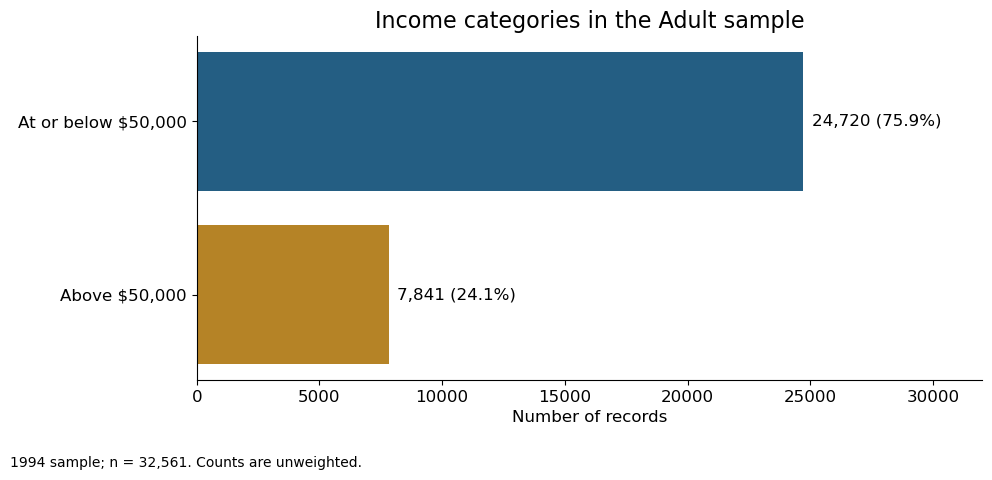

In [4]:
# Set a consistent style. Labels and numbers carry the meaning as well as color.
BLUE = "#245E83"
GOLD = "#B58326"
GRAY = "#E7E9EB"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 12,
                     "axes.titlesize": 16, "axes.labelsize": 12,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "savefig.facecolor": "white"})
counts = data["income"].value_counts().reindex(["<=50K", ">50K"])
fig, ax = plt.subplots(figsize=(10, 4.8))
bars = ax.barh(["At or below $50,000", "Above $50,000"], counts, color=[BLUE, GOLD])
ax.bar_label(bars, labels=[f"{n:,} ({100*n/len(data):.1f}%)" for n in counts], padding=6)
ax.set(xlim=(0, 32000), xlabel="Number of records", title="Income categories in the Adult sample")
ax.invert_yaxis()
fig.text(.01, .01, "1994 sample; n = 32,561. Counts are unweighted.", fontsize=10)
fig.tight_layout(rect=(0, .06, 1, 1))
fig.savefig(output_dir / "01_income_counts.png", dpi=180)
plt.show()

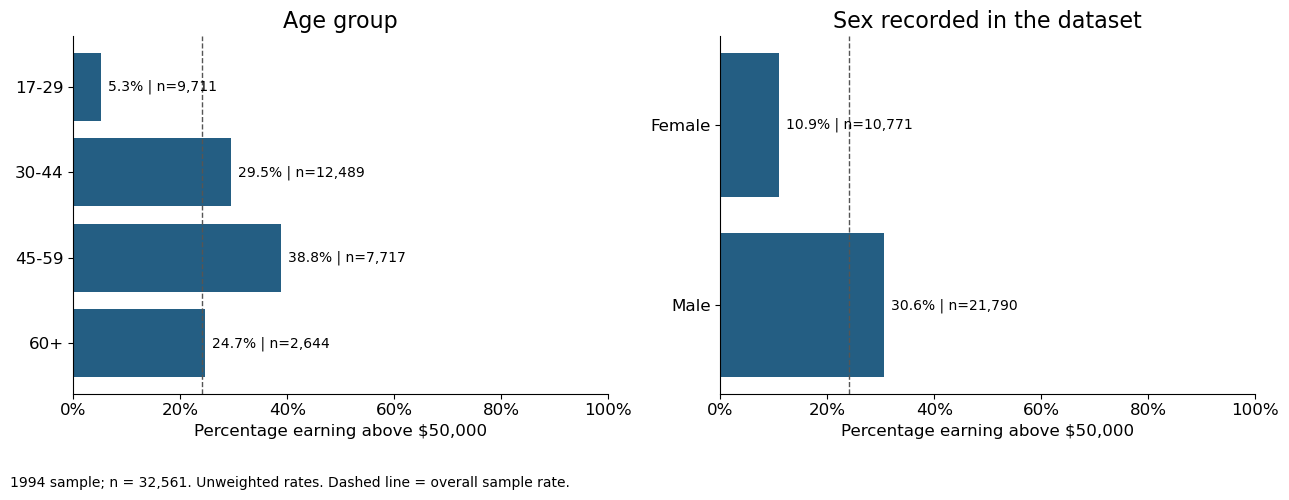

In [5]:
# Compare demographic groups using percentages rather than unequal group counts.
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, field, order, title in zip(axes,
        ["age_band", "sex"], [age_order, ["Female", "Male"]], ["Age group", "Sex recorded in the dataset"]):
    table = group_tables[field].reindex(order)
    bars = ax.barh(table.index, table["percent_above_50k"], color=BLUE)
    ax.bar_label(bars, labels=[f"{r.percent_above_50k:.1f}% | n={r.n:,}" for r in table.itertuples()], padding=5, fontsize=10)
    ax.axvline(overall_percent, color="#555555", linestyle="--", linewidth=1)
    ax.set(xlim=(0, 100), xlabel="Percentage earning above $50,000", title=title)
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.invert_yaxis()
fig.text(.01, .01, "1994 sample; n = 32,561. Unweighted rates. Dashed line = overall sample rate.", fontsize=10)
fig.tight_layout(rect=(0, .07, 1, 1))
fig.savefig(output_dir / "02_demographics.png", dpi=180)
plt.show()

### Education and employment
The next plots compare education, occupation, and weekly work hours separately.
These differences do not isolate the effect of one variable from the others.
The occupation plot includes all categories, including unknown occupation.
The Armed-Forces category has only nine records and is too small for a stable comparison.

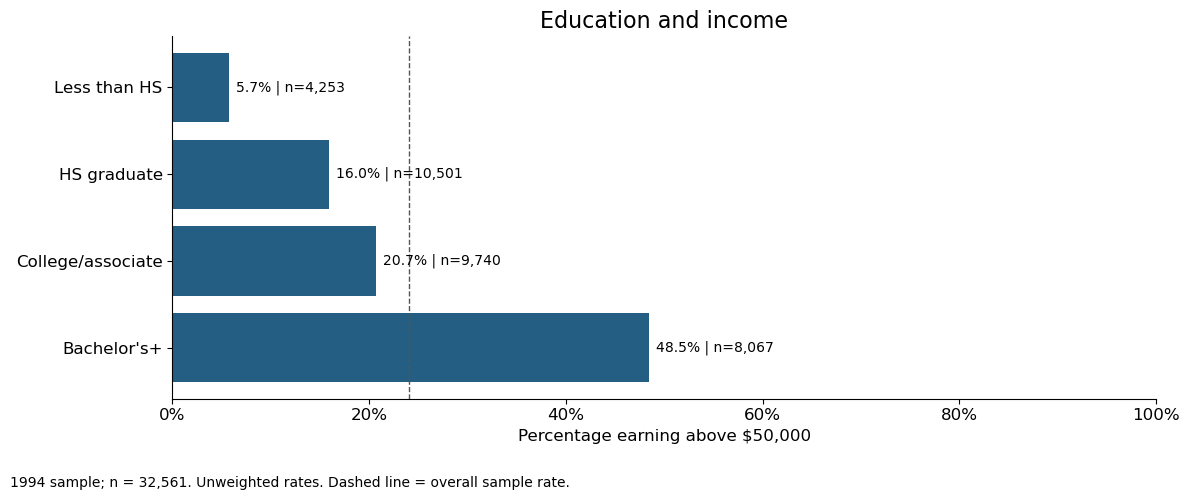

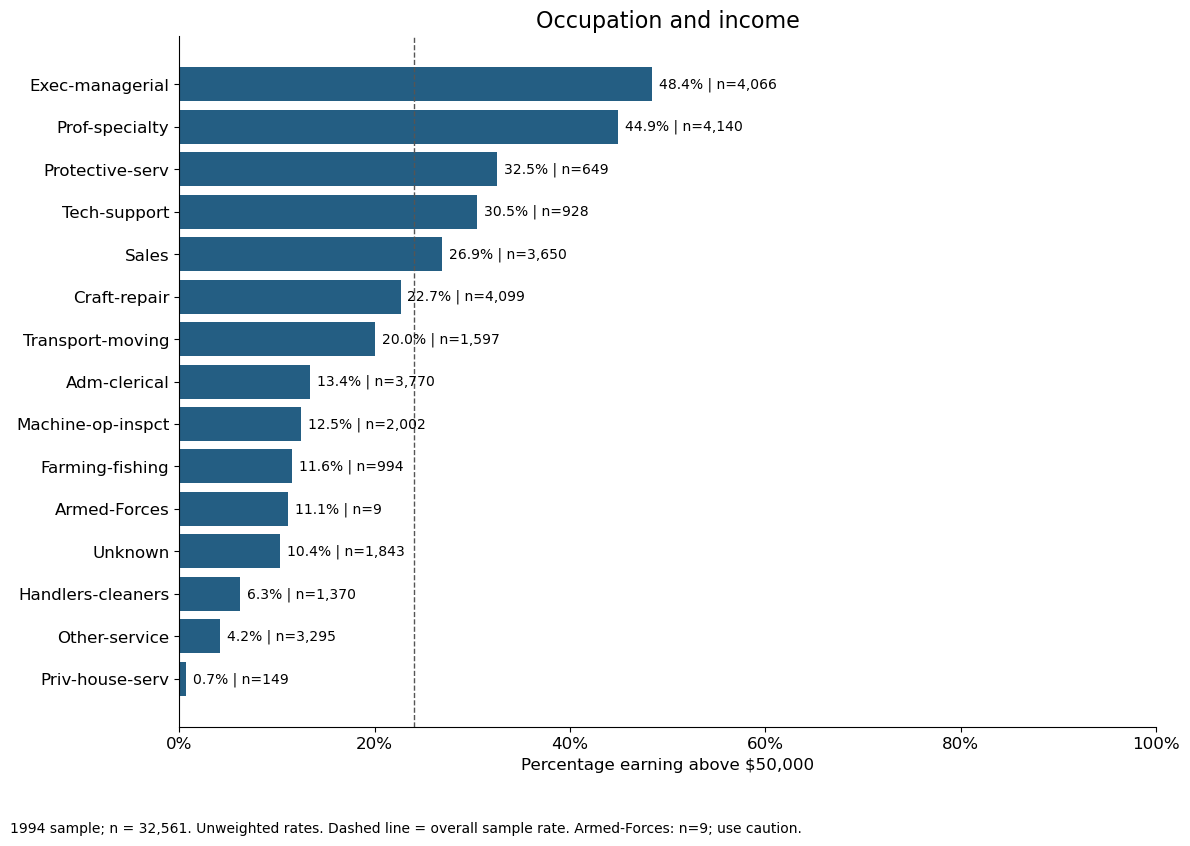

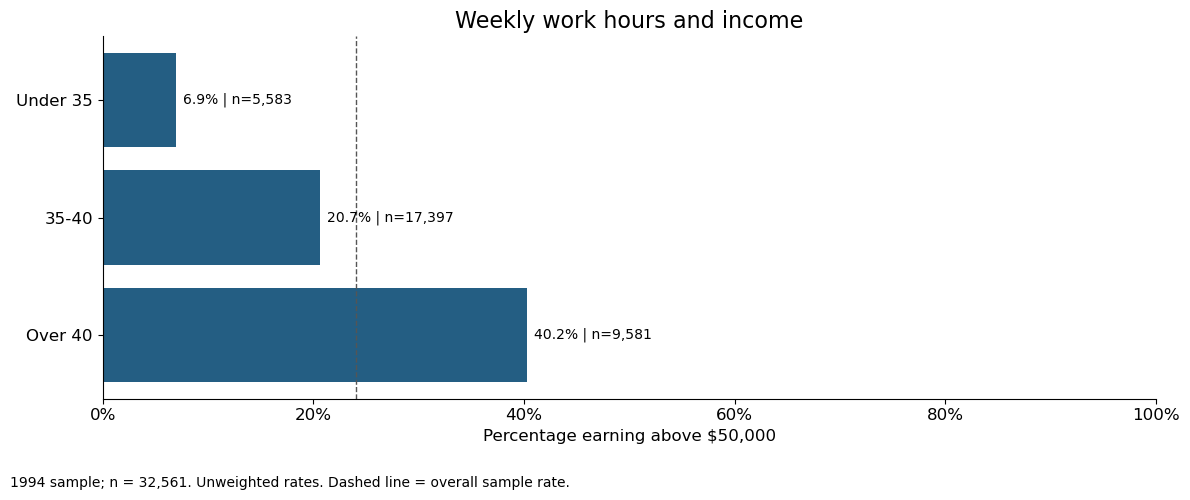

In [6]:
# Use the full set of groups, keeping meaningful ordering where it applies.
for field, order, title, filename in [
    ("education_band", education_order, "Education and income", "03_education.png"),
    ("occupation_display", None, "Occupation and income", "04_occupation.png"),
    ("hours_band", hours_order, "Weekly work hours and income", "05_hours.png")]:
    table = group_tables[field]
    table = table.reindex(order) if order is not None else table.sort_values("percent_above_50k", ascending=False)
    fig, ax = plt.subplots(figsize=(12, 8.5 if field == "occupation_display" else 5))
    bars = ax.barh(table.index, table["percent_above_50k"], color=BLUE)
    ax.bar_label(bars, labels=[f"{r.percent_above_50k:.1f}% | n={r.n:,}" for r in table.itertuples()], padding=5, fontsize=10)
    ax.axvline(overall_percent, color="#555555", linestyle="--", linewidth=1)
    ax.set(xlim=(0, 100), xlabel="Percentage earning above $50,000", title=title)
    ax.xaxis.set_major_formatter(PercentFormatter(100))
    ax.invert_yaxis()
    note = "1994 sample; n = 32,561. Unweighted rates. Dashed line = overall sample rate."
    if field == "occupation_display":
        note += " Armed-Forces: n=9; use caution."
    fig.text(.01, .01, note, fontsize=10)
    fig.tight_layout(rect=(0, .06, 1, 1))
    fig.savefig(output_dir / filename, dpi=180)
    plt.show()

### Combined characteristics
The heatmaps compare **age, education, and weekly work hours together**.
Each cell shows the percentage above $50,000 and the number of records in that combination.
Both panels use the same 0–100% scale. Cells with fewer than 100 records are gray
and show the count only; this is a display rule, not a statistical significance test.
All records remain in the analysis and in the saved summary table.

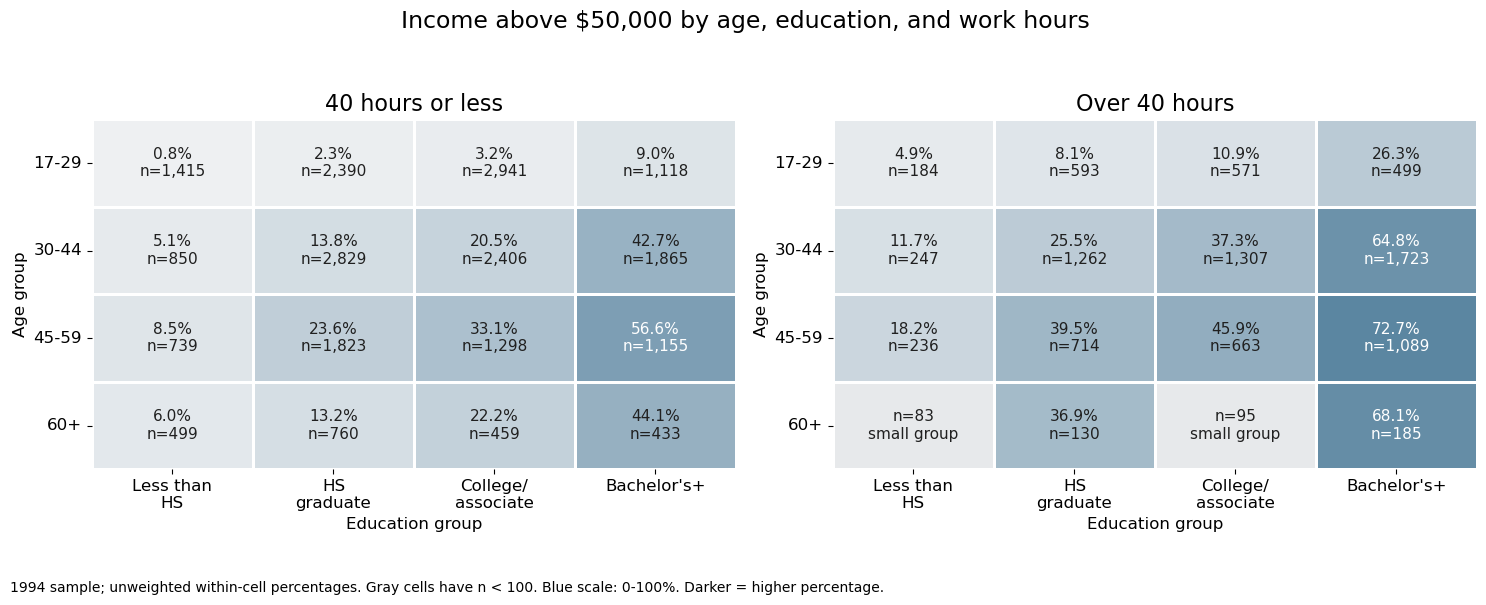

In [7]:
# Aggregate numerator and denominator for every age/education/hours combination.
joint = data.groupby(["hours_comparison", "age_band", "education_band"], observed=False)["income_high"].agg(n="size", above_50k="sum")
joint["percent_above_50k"] = 100 * joint["above_50k"] / joint["n"].replace(0, np.nan)
assert joint["n"].sum() == len(data)
minimum_cell_n = 100
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cmap = sns.light_palette(BLUE, as_cmap=True)
for ax, hours in zip(axes, ["40 hours or less", "Over 40 hours"]):
    part = joint.loc[hours]
    rates = part["percent_above_50k"].unstack().reindex(index=age_order, columns=education_order)
    sizes = part["n"].unstack().reindex(index=age_order, columns=education_order)
    ax.set_facecolor(GRAY)
    sns.heatmap(rates, mask=sizes < minimum_cell_n, annot=False, cmap=cmap,
                vmin=0, vmax=100, linewidths=1, linecolor="white", cbar=False,
                ax=ax)
    # Label every cell explicitly for compatibility with the installed plotting versions.
    # Small groups show only their count, so an unstable rate is not emphasized.
    for i in range(len(age_order)):
        for j in range(len(education_order)):
            n = int(sizes.iloc[i, j])
            rate = rates.iloc[i, j]
            label = f"{rate:.1f}%\nn={n:,}" if n >= minimum_cell_n else f"n={n:,}\nsmall group"
            color = "white" if n >= minimum_cell_n and rate >= 55 else "#202020"
            ax.text(j + .5, i + .5, label, ha="center", va="center", fontsize=11, color=color)
    assert len(ax.texts) == rates.size
    ax.set(title=hours, xlabel="Education group", ylabel="Age group")
    ax.set_xticklabels(["Less than\nHS", "HS\ngraduate", "College/\nassociate", "Bachelor's+"], rotation=0)
    ax.set_yticklabels(age_order, rotation=0)
fig.suptitle("Income above $50,000 by age, education, and work hours", fontsize=17)
fig.text(.01, .01, "1994 sample; unweighted within-cell percentages. Gray cells have n < 100. Blue scale: 0-100%. Darker = higher percentage.", fontsize=10)
fig.tight_layout(rect=(0, .08, 1, .94))
fig.savefig(output_dir / "06_combined_characteristics.png", dpi=180)
plt.show()

### Additional context
Workclass and marital status offer other possible variables for later classification.
The tables below report group sizes and rates without claiming that they explain a difference independently.

In [8]:
# Keep exact values available alongside the main charts.
for field in ["workclass", "marital-status"]:
    print(field)
    display(group_tables[field].round({"percent_above_50k": 2}))

workclass


,n,above_50k,percent_above_50k
workclass,,,
Federal-gov,960,371,38.65
Local-gov,2093,617,29.48
Never-worked,7,0,0.00
Private,22696,4963,21.87
Self-emp-inc,1116,622,55.73
Self-emp-not-inc,2541,724,28.49
State-gov,1298,353,27.20
Unknown,1836,191,10.40
Without-pay,14,0,0.00


marital-status


,n,above_50k,percent_above_50k
marital-status,,,
Divorced,4443,463,10.42
Married-AF-spouse,23,10,43.48
Married-civ-spouse,14976,6692,44.68
Married-spouse-absent,418,34,8.13
Never-married,10683,491,4.60
Separated,1025,66,6.44
Widowed,993,85,8.56


### Checks
Recompute each chart percentage directly from row filters, check that group counts add up,
and confirm the source file stayed unchanged. Also check how much the overall percentage
changes if the 24 repeated profiles are removed.

In [9]:
# This independent calculation would fail if a group percentage used the wrong denominator.
for field, table in group_tables.items():
    labels = data[field].astype("string").fillna("Unknown")
    for label, row in table.iterrows():
        members = labels.eq(str(label))
        numerator = int((members & data["income"].eq(">50K")).sum())
        assert numerator == row["above_50k"] and int(members.sum()) == row["n"]
        assert np.isclose(100 * numerator / members.sum(), row["percent_above_50k"])
for (hours, age, education), row in joint.iterrows():
    members = data["hours_comparison"].eq(hours) & data["age_band"].eq(age) & data["education_band"].eq(education)
    assert int(members.sum()) == row["n"]
    assert int(data.loc[members, "income_high"].sum()) == row["above_50k"]
assert int(data["income_high"].sum()) == 7841
assert hashlib.sha256(data_file.read_bytes()).hexdigest() == source_hash
assert raw.equals(pd.read_csv(data_file, dtype="string", keep_default_na=False))
without_repeats = data.drop_duplicates(subset=columns)
repeat_effect_pp = 100 * without_repeats["income_high"].mean() - overall_percent
print("PASS: group counts, percentages, joint cells, and unchanged source.")
print(f"Removing repeated profiles changes the overall rate by {repeat_effect_pp:+.4f} percentage points.")

PASS: group counts, percentages, joint cells, and unchanged source.
Removing repeated profiles changes the overall rate by +0.0116 percentage points.


## 4. Report
The findings below are calculated from the tables used for the charts.

In [10]:
# Report observed comparisons without treating them as causal effects.
age_table = group_tables["age_band"].reindex(age_order)
education_table = group_tables["education_band"].reindex(education_order)
hours_table = group_tables["hours_band"].reindex(hours_order)
occupation_table = group_tables["occupation_display"]
eligible = joint[joint["n"] >= minimum_cell_n].sort_values("percent_above_50k", ascending=False)
highest = eligible.iloc[0]
highest_hours, highest_age, highest_education = eligible.index[0]
report = f"""### Findings
- **Overall:** {int(data['income_high'].sum()):,} of {len(data):,} records ({overall_percent:.1f}%) earn above $50,000.
- **Age:** The largest age-group rate is {age_table['percent_above_50k'].idxmax()} at {age_table['percent_above_50k'].max():.1f}%. Income does not rise steadily across every age band.
- **Education:** {education_table.loc["Bachelor's+", 'percent_above_50k']:.1f}% of the bachelor's-or-higher group earn above $50,000, compared with {education_table.loc['HS graduate', 'percent_above_50k']:.1f}% of high school graduates.
- **Occupation:** Executive/managerial and professional-specialty rates are {occupation_table.loc['Exec-managerial', 'percent_above_50k']:.1f}% and {occupation_table.loc['Prof-specialty', 'percent_above_50k']:.1f}%, respectively.
- **Hours:** The rate is {hours_table.loc['Over 40', 'percent_above_50k']:.1f}% for over 40 hours per week and {hours_table.loc['35-40', 'percent_above_50k']:.1f}% for 35–40 hours.
- **Combined view:** The highest rate among cells with at least {minimum_cell_n} records is {highest.percent_above_50k:.1f}% for age {highest_age}, {highest_education}, and {highest_hours.lower()} (n={int(highest.n):,}). This is the highest displayed combination, not an adjusted predictor ranking.

### What this means
The descriptive patterns are consistent with the broader hypothesis. Education, age,
occupation, and work hours all show differences, and the combined view shows why a single
education comparison is incomplete. These results do not establish each variable's independent
effect or prove the hypothesis. A later classification analysis can examine the variables together.

### Limits
The data are from 1994 and use broad income categories. The summaries are unweighted.
Missing occupations remain a separate group. Small groups can produce unstable percentages.
Differences across recorded sex categories may reflect other measured or unmeasured factors.
No causal conclusion, predictive accuracy claim, or action recommendation is made.
This project ends at **Step 4: Report**.
"""
display(Markdown(report))

# Save chart values so the slides and notebook can be checked against the same results.
summary = {"source_sha256": source_hash, "rows": len(data), "columns_in_source": len(columns),
           "above_50k": int(data["income_high"].sum()), "overall_percent": overall_percent,
           "missing": {k: int(v) for k, v in missing.items() if v},
           "missing_rows": missing_rows, "repeated_profiles": repeat_count,
           "repeat_effect_pp": repeat_effect_pp, "versions": versions,
           "minimum_cell_n": minimum_cell_n,
           "groups": {k: json.loads(v.reset_index().to_json(orient="records")) for k,v in group_tables.items()},
           "joint": json.loads(joint.reset_index().to_json(orient="records")),
           "report_markdown": report}
_ = (output_dir / "analysis_summary.json").write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n")

### Findings
- **Overall:** 7,841 of 32,561 records (24.1%) earn above $50,000.
- **Age:** The largest age-group rate is 45-59 at 38.8%. Income does not rise steadily across every age band.
- **Education:** 48.5% of the bachelor's-or-higher group earn above $50,000, compared with 16.0% of high school graduates.
- **Occupation:** Executive/managerial and professional-specialty rates are 48.4% and 44.9%, respectively.
- **Hours:** The rate is 40.2% for over 40 hours per week and 20.7% for 35–40 hours.
- **Combined view:** The highest rate among cells with at least 100 records is 72.7% for age 45-59, Bachelor's+, and over 40 hours (n=1,089). This is the highest displayed combination, not an adjusted predictor ranking.

### What this means
The descriptive patterns are consistent with the broader hypothesis. Education, age,
occupation, and work hours all show differences, and the combined view shows why a single
education comparison is incomplete. These results do not establish each variable's independent
effect or prove the hypothesis. A later classification analysis can examine the variables together.

### Limits
The data are from 1994 and use broad income categories. The summaries are unweighted.
Missing occupations remain a separate group. Small groups can produce unstable percentages.
Differences across recorded sex categories may reflect other measured or unmeasured factors.
No causal conclusion, predictive accuracy claim, or action recommendation is made.
This project ends at **Step 4: Report**.


## References
- Becker, B., & Kohavi, R. (1996). *Adult* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5XW20
- UCI attribute definitions and survey weights: https://archive.ics.uci.edu/ml/machine-learning-databases/adult/adult.names
- Matplotlib documentation: https://matplotlib.org/stable/users/index.html
- Seaborn heatmap documentation: https://seaborn.pydata.org/generated/seaborn.heatmap.html